<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/UTS/kmeans_euclidean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# KMEANS — Euclidean


In [1]:
pip install scikit-learn-extra

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 3.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2154567 sha256=a49806a277d12c88c732d43b4ef5da00182a90a6b0992444ca1844a6129ee43c
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


In [2]:
import time
import tracemalloc
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn_extra.cluster import KMedoids

default_data = next(
    (path for path in (Path("data/cafes.csv"), Path("cafes.csv")) if path.is_file()),
    Path("data/cafes.csv"),
)
DATA_PATH = Path(globals().get("DATA_PATH", default_data)).expanduser().resolve()
FIGURES_DIR = Path(globals().get("FIGURES_DIR", Path("reports/figures"))).expanduser().resolve()
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"CSV tidak ditemukan: {DATA_PATH}. Buka notebook dari folder paket "
        "atau tentukan DATA_PATH ke lokasi CSV Anda."
    )
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
# ==============================================================================
# BAGIAN A: LOAD DATA & PREPROCESSING (MURNI FITUR NUMERIK KAFE)
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN A: LOAD DATA & PREPROCESSING")
print("="*56)

df = pd.read_csv(DATA_PATH, on_bad_lines="skip")

# Kolom fitur numerik kafe
kolom_fitur = ['latitude', 'longitude', 'rating', 'review_count']
kolom_ada = [k for k in kolom_fitur if k in df.columns]

# Ambil kolom numerik dan hapus baris bernilai kosong
df_fitur = df[kolom_ada].dropna()

# Standarisasi data dengan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_fitur)

print(f"Data siap | Fitur: {kolom_ada}")
print(f"Bentuk Matriks (Shape): {X_scaled.shape} | Baris Sampel: {len(df_fitur)}")



  BAGIAN A: LOAD DATA & PREPROCESSING
Data siap | Fitur: ['latitude', 'longitude', 'rating', 'review_count']
Bentuk Matriks (Shape): (215, 4) | Baris Sampel: 215



  BAGIAN B: ELBOW METHOD (K=2 HINGGA 10)


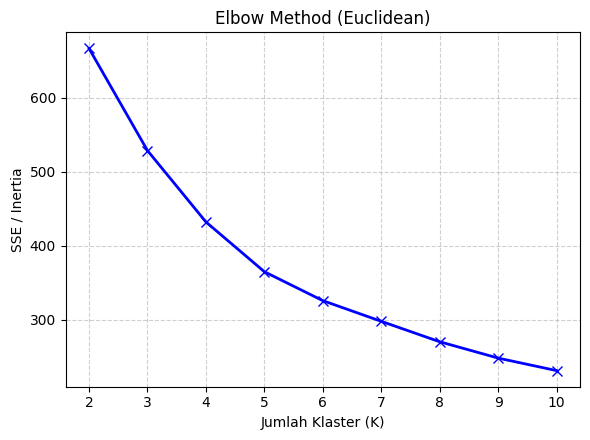

Grafik Elbow disimpan ke: /content/reports/figures/kmeans_euclidean_elbow_plots.png


In [4]:
# ==============================================================================
# BAGIAN B: ELBOW METHOD (UNTUK MENENTUKAN K TERBAIK)
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN B: ELBOW METHOD (K=2 HINGGA 10)")
print("="*56)

K_range = range(2, 11)

# 1. Elbow Euclidean
sse_euclid = []
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    sse_euclid.append(km.inertia_)


plt.figure(figsize=(6, 4.5))
plt.plot(list(K_range), sse_euclid, 'bx-', linewidth=2, markersize=7)
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('SSE / Inertia')
plt.title('Elbow Method (Euclidean)')
plt.xticks(list(K_range))
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
elbow_plot_path = FIGURES_DIR / "kmeans_euclidean_elbow_plots.png"
plt.savefig(elbow_plot_path, dpi=150)
plt.show()
plt.close()
print(f"Grafik Elbow disimpan ke: {elbow_plot_path}")

# Nilai K terbaik
K_TERBAIK_EUCLID = 4


In [5]:
# --- 1. K-MEANS EUCLIDEAN ---
print("\n" + "="*56)
print("  K-MEANS — METRIK: EUCLIDEAN")
print("="*56)
tracemalloc.start()
t_mulai = time.time()

km_euclid = KMeans(n_clusters=K_TERBAIK_EUCLID, random_state=42, n_init=10)
lbl_euclid = km_euclid.fit_predict(X_scaled)

t_selesai = time.time()
_, mem_puncak = tracemalloc.get_traced_memory()
tracemalloc.stop()

sil_euclid = silhouette_score(X_scaled, lbl_euclid, metric='euclidean')
waktu_euclid = t_selesai - t_mulai
mem_euclid_kb = mem_puncak / 1024
mem_euclid_mb = mem_puncak / (1024**2)

print(f"  Jumlah Klaster    : {K_TERBAIK_EUCLID}")
print(f"  Waktu Eksekusi    : {waktu_euclid:.4f} detik")
print(f"  Memori Puncak     : {mem_euclid_kb:.2f} KB ({mem_euclid_mb:.4f} MB)")
print(f"  Silhouette Score  : {sil_euclid:.4f}")
print("="*56)



  K-MEANS — METRIK: EUCLIDEAN
  Jumlah Klaster    : 4
  Waktu Eksekusi    : 0.1990 detik
  Memori Puncak     : 46.23 KB (0.0451 MB)
  Silhouette Score  : 0.2646



  BAGIAN D: VISUALISASI PCA 2D (K-MEANS)


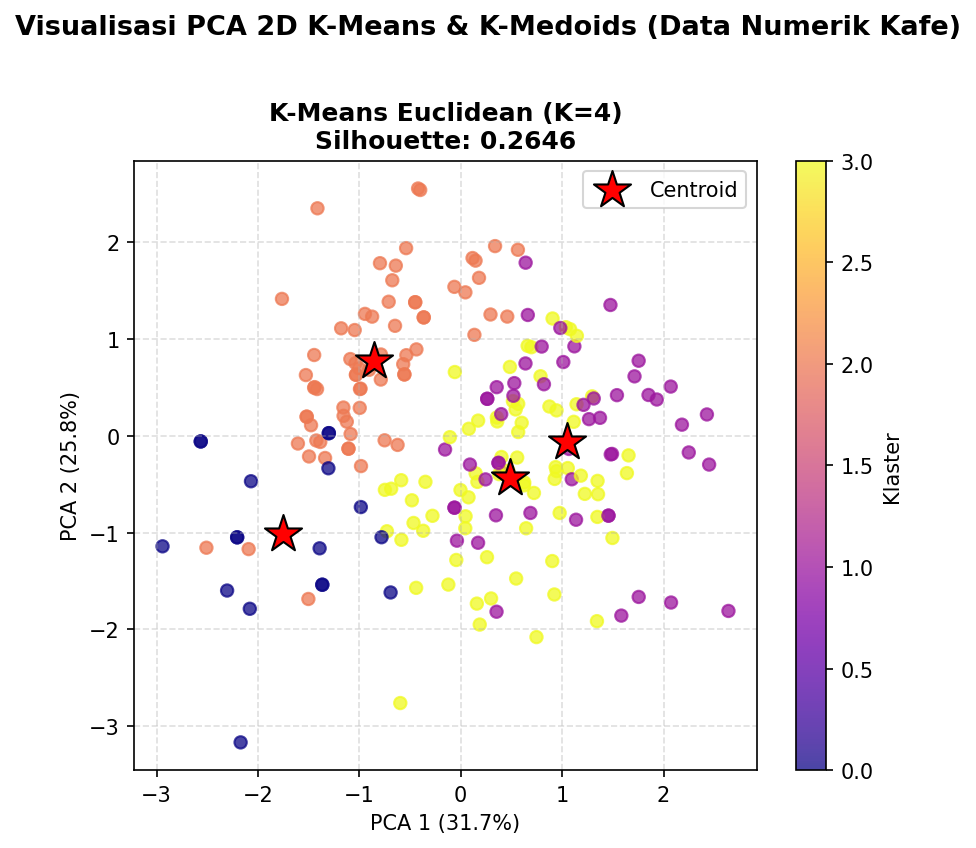

Visualisasi PCA disimpan ke: /content/reports/figures/kmeans_euclidean_pca_plots.png


In [6]:
# ==============================================================================
# BAGIAN D: VISUALISASI PCA 2D DENGAN CENTROID BINTANG MERAH
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN D: VISUALISASI PCA 2D (K-MEANS)")
print("="*56)

pca = PCA(n_components=2, random_state=42)
X_pca_std = pca.fit_transform(X_scaled)
v1_std, v2_std = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(6, 5.5), dpi=150)
axes = [ax]
# 1. Plot Euclidean
cen_e = pca.transform(km_euclid.cluster_centers_)
sc1 = axes[0].scatter(X_pca_std[:, 0], X_pca_std[:, 1], c=lbl_euclid, cmap='plasma', s=35, alpha=0.75)
axes[0].scatter(cen_e[:, 0], cen_e[:, 1], c='red', marker='*', s=350, zorder=5, label='Centroid', edgecolors='black')
axes[0].set_title(f"K-Means Euclidean (K={K_TERBAIK_EUCLID})\nSilhouette: {sil_euclid:.4f}", fontweight='bold')
axes[0].set_xlabel(f'PCA 1 ({v1_std:.1f}%)')
axes[0].set_ylabel(f'PCA 2 ({v2_std:.1f}%)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.4)
plt.colorbar(sc1, ax=axes[0], label='Klaster')

plt.suptitle("Visualisasi PCA 2D K-Means & K-Medoids (Data Numerik Kafe)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
pca_plot_path = FIGURES_DIR / "kmeans_euclidean_pca_plots.png"
plt.savefig(pca_plot_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print(f"Visualisasi PCA disimpan ke: {pca_plot_path}")


In [7]:
# Dictionary ringkasan performa untuk pelaporan
KMEANS_SUMMARY = {
    "euclidean": {
        "algo": "K-Means", "metric": "Euclidean", "param": f"K={K_TERBAIK_EUCLID}",
        "time": waktu_euclid, "mem_mb": mem_euclid_mb, "clusters": K_TERBAIK_EUCLID,
        "noise_pct": 0.0, "silhouette": sil_euclid, "labels": lbl_euclid
    }
}
